In [1]:
# run first
%load_ext autoreload
%autoreload 2

#### Imports

In [2]:
import os
import cupy as cp
import numpy as np
import matplotlib.pyplot as plt

from aicspylibczi import CziFile
from PIL import Image, ImageDraw, ImageFont
from pipeline.methods import to_directory, read_czi, read_yaml, read_beads, read_h5, \
     read_shape, read_kernel, to_mip, to_shift, configure_plots, to_shifted, to_ellipsoid, \
     make_color, to_fmt, segmentation, detection, finding, deskewing, deconvolution, get_slice
import math
import cupyx.scipy.ndimage as ndi

from numba import jit
from pipeline.methods.utilities import proc, read_h5, mkdir, to_log, \
     to_fmt, fracshift
from pipeline.methods.detection import mark

import cv2

### Commands

#### 0. Find beads (all CZIs)
``` bash
python beads.py -b beads.txt -c config.yaml -m finding
```

#### 1. Segment nuclei (single CZI)
``` bash
python segmentation.py -f file.czi -c config.yaml
```

#### 2. Track nuclei
``` bash
python tracking.py -f file.czi -c config.yaml -mode nuclei
```

#### 3. Detect features (within nuclei)
``` bash
python detection.py -f file.czi -c config.yaml
```

#### 4. Track features (within nuclei)
``` bash
python tracking.py -f file.czi -c config.yaml -m features
```

#### 5. Fitting chromatic aberrations (and bead intensities)
``` bash
python beads.py -f file.czi -b beads.txt -c config.yaml -m fitting
```

#### 6. Measure feature tracks
``` bash
python measuring.py -f file.czi -b beads.txt -c config.yaml
```

#### Configure

In [11]:
# inputs
# file = "../../../projects/synEP/movies/20250219/G7B8G2_GSK_500uMdTAG13added2hrBefore_30ms_0_3umIntervals_15by650_30sFrameRate-02.czi"
file = "/mnt/md1/Jamie/raw/20260314/20260314_txn-05.czi/20260314_txn-05_AcquisitionBlock1.czi/20260314_txn-05_AcquisitionBlock1.czi"
beads = "beads.txt"
psf = "/mnt/md0/Jamie/LatticeProcessing/JD_PSFs.h5"
# directory = '/mnt/hildeshareslocal/Jamie/processed/unt/20260402_1' # untreated example nucleus is 10
directory = '//mnt/hildeshareslocal/Jamie/processed/txn/20260330_3' # txn example nucleus is 25
config = "config.yaml"

# read CZI and config
czi = CziFile(file)
print(czi.size)
c = read_yaml(config)

# path to steps/nuclei
frames_path = os.path.join(directory, "frames")
nuclei_path = os.path.join(directory, "nuclei")

# get PSF parameters
lasers = c["general"]["lasers"]
kernel = read_kernel(psf, lasers)
shape = read_shape(psf, lasers)

# set GPU and plot formatting
device = 1
configure_plots()

(360, 3, 500, 228, 2048)


#### Read

In [4]:
# read a frame
frame = 43
signal = read_czi(file, frame)

### Deskewing

In [5]:
# deskew all channels
c = read_yaml(config)
with cp.cuda.Device(device):
    deskew = deskewing(signal, **c["deskewing"])

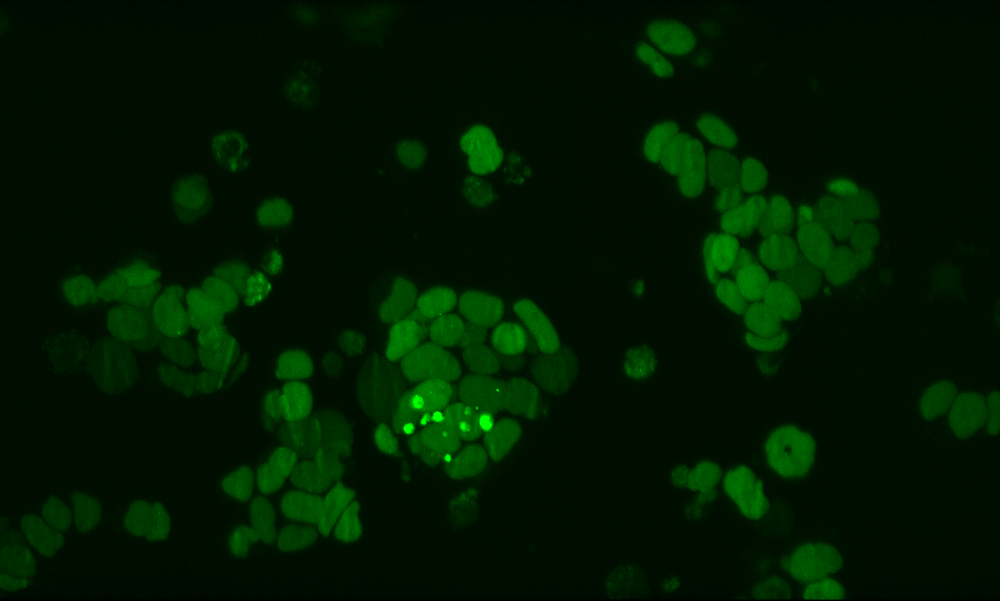

In [6]:
# make MIP and show
chnl = 1
mip = to_mip(deskew[chnl], **c["movies"]["channels"][chnl], axis=0)
display(Image.fromarray(np.transpose(mip, axes=(1,0,2))))

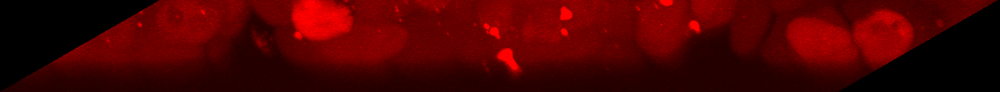

In [7]:
# make MIP and show
chnl = 2
mip = to_mip(deskew[chnl], **c["movies"]["channels"][chnl], axis=1)
display(Image.fromarray(np.flipud(mip)))

### Deconvolution

In [7]:
# deconvolve all channels
c = read_yaml(config)
with cp.cuda.Device(device):
    deconvolve = deconvolution(deskew, kernel, **c["deconvolution"])

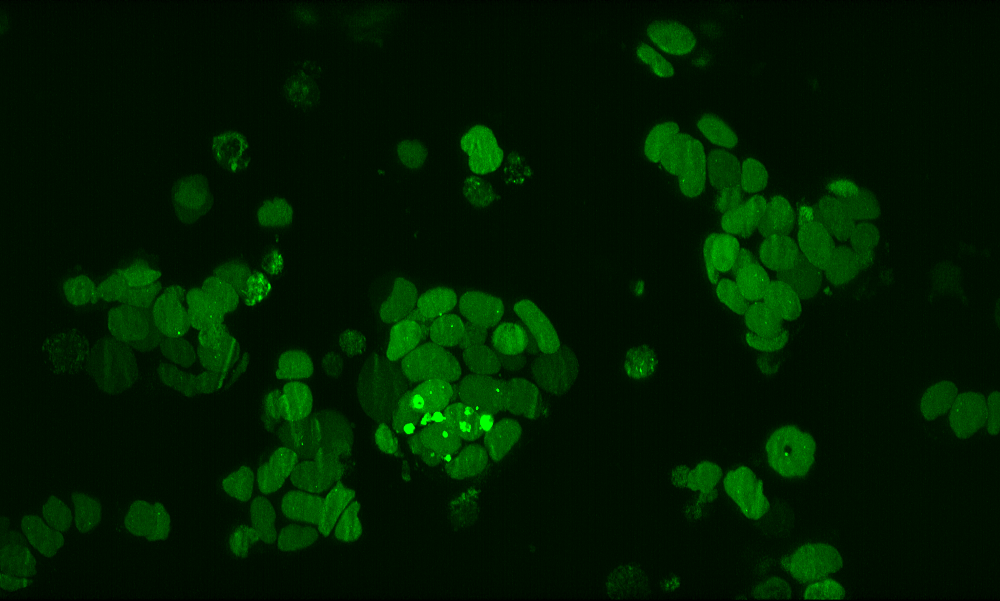

In [8]:
# make MIP and show
c = read_yaml(config)
chnl = 1
mip = to_mip(deconvolve[chnl], **c["movies"]["channels"][chnl], axis=0)
display(Image.fromarray(np.transpose(mip, axes=(1,0,2))))

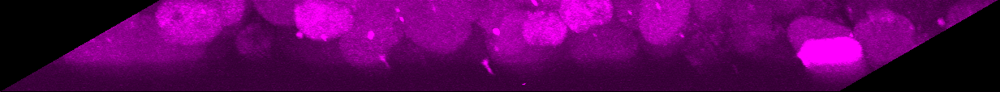

In [12]:
# make MIP and show
chnl = 0
mip = to_mip(deconvolve[chnl], **c["movies"]["channels"][chnl], axis=1)
display(Image.fromarray(np.flipud(mip)))

### Segmentation

In [9]:
# segment nuclei
c = read_yaml(config)
with cp.cuda.Device(device):
    labels, info = segmentation(deconvolve, **c["segmentation"])

#### Show nuclei labels

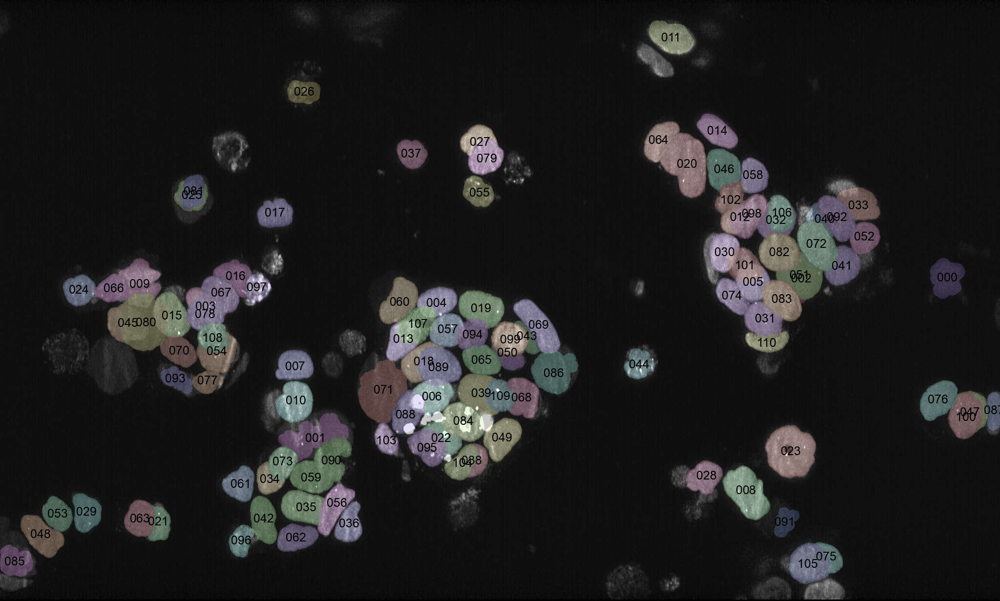

In [10]:
# make MIP
c = read_yaml(config)
# chnl = c["segmentation"]["channel"]
chnl=1
mip = to_mip(deconvolve[chnl], **c["movies"]["channels"][chnl], gray=True, axis=0)
mip = np.clip(mip, 0, 200)  # clip for adding labels

# add color to MIP
mip_labels = np.max(labels, axis=0)
for i in range(len(info)):
    mip[mip_labels == i] += (55*make_color()).astype(np.uint8)
mip = Image.fromarray(np.transpose(mip, axes=(1,0,2)))

# write labels
draw = ImageDraw.Draw(mip)
for i in range(len(info)):
    x, y, label = info[i,2], info[i,3], i
    draw.text(xy=(x-20,y-15),text=to_fmt(label),
              font=ImageFont.truetype(font="Arial", size=25), fill=(0,0,0))
display(mip)

#### Subset frame

In [ ]:
nucleus = 53

# get subset
l, u = info[nucleus,4:7].astype(int), info[nucleus,7:10].astype(int)
dcv = np.copy(deconvolve[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
dsk = np.copy(deskew[:,l[0]:u[0],l[1]:u[1],l[2]:u[2]])
mask = labels[l[0]:u[0],l[1]:u[1],l[2]:u[2]] == nucleus

#### Show nucleus

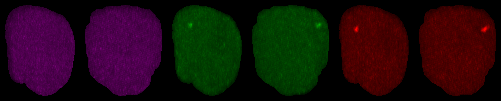

In [21]:
# make merged MIP of channels
mips = []
for chnl in range(len(dcv)):
    for axis in [0,1]:
        mip = to_mip(dcv[chnl], mask=mask, axis=axis, **c["movies"]["channels"][chnl])
        mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
mips = np.concatenate(mips, axis=1)
display(Image.fromarray(mips))

#### Registration of channels

In [16]:
# channels
# remember to change measuring module to register channel 0 to channel 1, not vice versa
ref, trg = 1, 0
with cp.cuda.Device(device):
    # run registration
    shift = to_shift(dsk[ref], dsk[trg])
    print(f"z: {shift[0]:.2f} y: {shift[1]:.2f} x: {shift[2]:.2f}")

z: -0.04 y: -3.00 x: 0.02


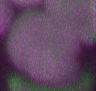

In [17]:
# make MIPs of channels
ref_mip = to_mip(dsk[ref], **c["movies"]["channels"][ref], axis=0)
trg_mip = to_mip(to_shifted(dsk[trg], shift), **c["movies"]["channels"][trg], axis=0)
display(Image.fromarray(np.transpose(np.maximum(ref_mip, trg_mip), axes=(1,0,2))))

### Detection

#### Detect in channels

In [22]:
# detect features
c = read_yaml(config)
with cp.cuda.Device(device):
    features = detection(dcv, dsk, mask, shape, **c["detection"])

#### Show detections

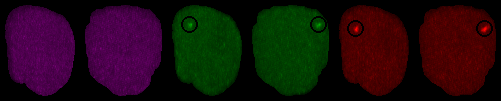

In [23]:
# make merged MIP of channels
mips = []
for chnl in range(len(dcv)):
    for axis in [0,1]:
        mip = to_mip(dcv[chnl], mask=mask, axis=axis, **c["movies"]["channels"][chnl])
        mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
mips = Image.fromarray(np.concatenate(mips, axis=1))

# show detections
draw, radius = ImageDraw.Draw(mips), 8
offset = np.sum(dcv.shape[1:3])
for chnl in c["detection"]["channels"]:
    pts = features[chnl]
    for j in range(len(pts)):
        color= "yellow" if pts[j,-1] else "black"
        x, y = pts[j,4] + chnl*offset, pts[j,5]
        draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
        x, y = pts[j,3] + chnl*offset + dcv.shape[2], pts[j,5]
        draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
display(mips)

#### Show detected within nucleus

In [5]:
# read nucleus track
nucleus = 10
nucleus_track = np.loadtxt(os.path.join(nuclei_path, f"{to_fmt(nucleus)}", "info.csv"),
                           delimiter=",", skiprows=1)

In [9]:
def test_detection(dcv, dsk, mask, shape, channels={}, nearby=10.0, sister=5.0):
    """
    Defines detection method and filters any
    detected features.

    Parameters
    ----------
    dcv : numpy.ndarray
        Deconvolved signal subset around nucleus.
    dsk : numpy.ndarray
        Deskewed signal subset around nucleus.
    mask : numpy.ndarray
        Mask subset for nucleus.
    shape : numpy.ndarray
        Shape of PSF masks for each channel.
    channels : dict, optional
        Channels (with parameters) to detect features.
    nearby : float, optional
        Minimum separation between nearby features.
    sister : float, optional
        Maximum distance to designate sisters.

    Returns
    -------
    dict
        A dictionary with the features detected
        in each channel.
    """
    # get centroid
    centroid = np.mean(np.argwhere(mask).astype(float), axis=0)
        
    # find features in each channel
    features = dict.fromkeys(channels.keys())
    for chnl in channels:
        # handle channel config
        if "nearby" not in channels[chnl]:
            channels[chnl]["nearby"] = nearby
        if "sister" not in channels[chnl]:
            channels[chnl]["sister"] = sister
            
        # run SIFT-like detection and handle
        positions, sisters = test_detect(dcv[chnl], dsk[chnl], mask, 
                                    shape[chnl], **channels[chnl])
        if len(positions.shape) == 2:
            mapped = positions - centroid  # center positions
            features[chnl] = np.concatenate((mapped, positions, sisters.reshape(-1,1)), axis=1)
        else:
            features[chnl] = np.empty((0,7))
    
    return features


def test_detect(dcv, dsk, mask, shape, radius={}, response=300, nearby=10.0, sister=3.0):
    """
    SIFT-like method to finding features/dots
    of within nuclei.
    
    Parameters
    ----------
    dcv : numpy.ndarray
        Deconvolved (channel) signal subset around nucleus.
    dsk : numpy.ndarray
        Deskewed (channel) signal subset around nucleus.
    mask : numpy.ndarray
        Mask subset for nucleus.
    shape : numpy.ndarray
        Shape of PSF mask for channel.
    radius : dict, optional
        A dictionary containing a window of radii.
    response : float, optional
        Threshold for LoG filter response.
    nearby : float, optional
        Minimum separation between nearby features.
    sister : float, optional
        Maximum distance to designate sisters.

    Returns
    -------
    numpy.ndarray
        Positions of the detected features.
    numpy.ndarray
        Mask for sister detection of features.
    """
    # set up range of sigmas
    n = 10
    lower = radius["lower"] if "lower" in radius else 1.0
    upper = radius["upper"] if "upper" in radius else 3.0
    k = (upper/lower)**(1/(n-1))
    sigmas = lower/math.sqrt(2) * cp.array([(k**i) for i in range(0,n)])
    
    # move to GPU and estimate background
    dcv, mask = cp.array(dcv), cp.array(mask)
    background = cp.median(dcv[mask])
    # dcv[dcv == 0] = background  # testing
    
    # apply normalized LoG filters
    logs = cp.zeros((n, *dcv.shape), dtype=cp.float32)
    for i in range(n):
        logs[i] = -sigmas[i]**2 * to_log(dcv, sigmas[i])

    # find local maxima
    maxed = ndi.maximum_filter(logs, footprint=cp.ones((3,3,3,3)), mode="nearest")
    dots = (logs == maxed) * mask

    # get positions/responses and filter
    responses, positions = logs[dots], cp.argwhere(dots).astype(cp.float32)[:,1:]
    keep = responses >= (response * background / 1000)  # scale with background
    responses, positions = responses[keep].get(), positions[keep].get()

    # get best detections and pad deskew if nuclear localized
    ordering = np.argsort(responses)
    positions, responses = positions[ordering][-5:], responses[ordering][-5:]
    # get mask and mark nearby before refining positions
    mask = mask.get()
    sisters, keep = mark(positions, responses, nearby, sister)
    # # make fracshift mask for edge detection
    # fracshape = np.array([[17.0, 0., -3.7],
    #                   [ 0., 8.6,  0.],
    #                   [-3.7, 0., 12.7]],dtype='f')
    # fracmask = to_ellipsoid(fracshape)
    # fracmask = cp.array(fracmask)
    # # get edge mask
    # edgemask = cp.array(~mask)
    # edgemask = ndi.convolve(edgemask,fracmask,mode='nearest')
    # # print(np.all(edgemask))
    # # check if dot position falls within convolved edge mask and drop if it does
    # for i in range(len(positions)):
    #     if edgemask[*positions[i]]:
    #         keep[i] = 0
    # erode nuclear mask to remove faulty edge detections
    newmask = ndi.binary_erosion(cp.array(mask))
    for i in range(len(positions)):
        if ~newmask[*positions[i]]:
            keep[i]=0
    for i in range(len(positions)):   
        # refine position (mark if went out of volume)
        positions[i], inbounds = fracshift(dsk, positions[i], subtract=True,
                                           mask=mask, shape=shape, radius=7)
        keep[i] *= inbounds
    #TODO: add edge detection, reject detections that are too close to hard edges (i.e. have 0 w/in local neighborhood)
    # use ndi.convolve, convolve boolean mask of where edges are w/ fracshift mask
    # filter detections
    positions, sisters = positions[keep], sisters[keep]
    cp.get_default_memory_pool().free_all_blocks()
    
    return positions, sisters

In [ ]:
### DON'T RUN THIS CELL DIRECTLY
@proc
def detection_proc(nucleus, shape, directory, c, device):
    """
    Process job for detecting features within
    a nucleus.

    Parameters
    ----------
    nucleus : int
        Index for the tracked nucleus.
    shape : numpy.ndarray
        Shape of PSF masks for each channel.
    directory : str
        Path to the directory for input/outputs.
    c : dict
        Dictionary for config.
    device : int, optional
        GPU device to use.
    """
    # set CSV format
    #TODO: add absolute positions to this data
    fmt = 2*["%d"] + 6*["%.3f"] + ["%d"]
    header = "frame,label,z_map (px),y_map (px),x_map (px)," + \
             "z_sub (px),y_sub (px),x_sub (px),sisters"

    # make paths
    frames_path = os.path.join(directory, "frames")
    nuclei_path = os.path.join(directory, "nuclei")

    # get path to nucleus and read track
    nucleus_path = os.path.join(nuclei_path, to_fmt(nucleus))
    nucleus_track = np.loadtxt(os.path.join(nucleus_path, "info.csv"),
                               delimiter=",", skiprows=1, ndmin=2)
    # go through channels
    chnls_info = {}  # hold channel feature info
    chnls_path = mkdir(os.path.join(nucleus_path, "channels"))
    for chnl in c["detection"]["channels"]:
        chnls_info[chnl] = np.empty((0,9))
        mkdir(os.path.join(chnls_path, to_fmt(chnl)))

    # iterate through track
    for i in range(len(nucleus_track)):
        # get frame/label and path
        frame, label = int(nucleus_track[i,0]), int(nucleus_track[i,1])
        frame_path = os.path.join(frames_path, to_fmt(frame))
        
        # read mask/deskew/deconvolve for nucleus
        lbl = to_fmt(label)
        mask = read_h5(os.path.join(frame_path, "masks.h5"), lbl)
        dsk = read_h5(os.path.join(frame_path, "deskews.h5"), lbl)
        dcv = read_h5(os.path.join(frame_path, "deconvolves.h5"), lbl)
                
        # detect features for each channel
        with cp.cuda.Device(device):
            features = detection(dcv, dsk, mask, shape, **c["detection"])
        ## Add parts below here to the next cell
        # iterate through channels
        for chnl in c["detection"]["channels"]:
            # add frame and nucleus label (for tracking)
            info = np.empty((len(features[chnl]),9))
            info[:,0], info[:,1] = frame, label
            info[:,2:] = features[chnl]

            # append to info
            chnls_info[chnl] = np.concatenate((chnls_info[chnl], info), axis=0)
        
    # iterate through channels and save as CSV
    for chnl in c["detection"]["channels"]:
        info = chnls_info[chnl]
        np.savetxt(os.path.join(chnls_path, to_fmt(chnl), "info.csv"), info,
                   delimiter=",", fmt=fmt, header=header, comments="")

/mnt/hildeshareslocal/Jamie/processed/unt/20260402_1/nuclei/010
(27, 119)
(98, 118, 3)
(98, 118, 3)
(98, 118, 3)


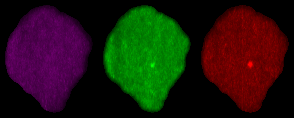

In [ ]:
# read nucleus track
c = read_yaml(config)
nucleus = 10
nucleus_track = np.loadtxt(os.path.join(nuclei_path, f"{to_fmt(nucleus)}", "info.csv"),
                           delimiter=",", skiprows=1)
print(os.path.join(nuclei_path, f"{to_fmt(nucleus)}"))
for i in range(26,27):
    # get frame/label
    frame, label = int(nucleus_track[i,0]), int(nucleus_track[i,1])
    frame_path = os.path.join(frames_path, f"{to_fmt(frame)}")
    print((frame,label))

    # read signal/mask and detect features
    lbl = f"{to_fmt(label)}"
    mask = read_h5(os.path.join(frame_path, "masks.h5"), lbl)
    dcv = read_h5(os.path.join(frame_path, "deconvolves.h5"), lbl)
    with cp.cuda.Device(device):
        features = detection(dcv, dcv, mask, shape, **c["detection"])

    # make merged MIP of channels
    mips = []
    for chnl in [1,2,0]:
        for axis in [0]:
            mip = to_mip(dcv[chnl], mask=mask, axis=axis, **c["movies"]["channels"][chnl])
            # print(mip)
            mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
            print(mip.shape)
    joint_mip = Image.fromarray(np.max(mips,axis=0))
    cv2.imwrite("/mnt/md0/Jamie/analysis/Figures/unt_example_nucleus_XY_mip.png",np.concatenate(mips,axis=1)[:,:,::-1])
    mips = Image.fromarray(np.concatenate(mips, axis=1))

    # # show detections
    # draw, radius = ImageDraw.Draw(mips), 8
    # offset = np.sum(dcv.shape[1:3])
    # for chnl in c["detection"]["channels"]:
    #     pts = features[chnl]
    #     for j in range(len(pts)):
    #         color= "yellow" if pts[j,-1] else "black"
    #         x, y = pts[j,4] + chnl*offset, pts[j,5]
    #         draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
    #         x, y = pts[j,3] + chnl*offset + dcv.shape[2], pts[j,5]
    #         draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
    display(mips)
    # display(joint_mip)

//mnt/hildeshareslocal/Jamie/processed/txn/20260330_3/nuclei/025
(27, 19)
(87, 288, 3)
[0 0 0]


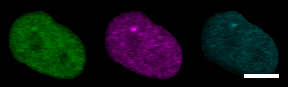

In [15]:
# 14px scale bar for 2um
# read nucleus track
c = read_yaml(config)
nucleus = 25
nucleus_track = np.loadtxt(os.path.join(nuclei_path, f"{to_fmt(nucleus)}", "info.csv"),
                           delimiter=",", skiprows=1)
print(os.path.join(nuclei_path, f"{to_fmt(nucleus)}"))
for i in range(26,27):
    # get frame/label
    frame, label = int(nucleus_track[i,0]), int(nucleus_track[i,1])
    frame_path = os.path.join(frames_path, f"{to_fmt(frame)}")
    print((frame,label))

    # read signal/mask and detect features
    lbl = f"{to_fmt(label)}"
    mask = read_h5(os.path.join(frame_path, "masks.h5"), lbl)
    dcv = read_h5(os.path.join(frame_path, "deconvolves.h5"), lbl)
    with cp.cuda.Device(device):
        features = detection(dcv, dcv, mask, shape, **c["detection"])

    # for i in np.arange(dcv.shape[1]):
    #     ims = []
    #     for chnl in range(len(dcv)):
    #         slc = get_slice(dcv[chnl],mask=mask,axis=0,ind=i,**c["movies"]["channels"][chnl])
    #         ims.append(slc)
    #     im_to_show = Image.fromarray(np.concatenate(ims,axis=1))
    #     print(i)
    #     display(im_to_show)

    ims = []
    best_i = 56
    for chnl in [1,2,0]:
        slc = get_slice(dcv[chnl],mask=mask,axis=0,ind=best_i,**c["movies"]["channels"][chnl])
        ims.append(slc)
    im_array = np.concatenate(ims,axis=1)
    print(im_array.shape)
    # configure scale bar
    padding = 10
    bar_height = 3
    bar_length = 34 # change this
    x2 = im_array.shape[1]-padding
    y2 = im_array.shape[0]-padding
    x1 = x2-bar_length
    y1 = y2-bar_height
    im_array_copy = im_array.copy()
    cv2.rectangle(im_array_copy,(x1,y1),(x2,y2),(255,255,255),-1)

    # textbox = cv2.getTextSize("5um",cv2.FONT_HERSHEY_SIMPLEX,0.85,2)
    # print(textbox)
    # text_x = x1+(bar_length-textbox[0][0])//2
    # text_y = y1-5
    # cv2.putText(im_array_copy,"5um",(text_x,text_y),cv2.FONT_HERSHEY_SIMPLEX,
    #             0.85,(255,255,255),2,cv2.LINE_AA)
    cv2.imwrite("/mnt/md0/Jamie/analysis/Figures/txn_example_nucleus_XY_slice_withbar.png",im_array_copy[:,:,::-1])
    print(im_array_copy[50,200,:])
    im_to_show = Image.fromarray(im_array_copy)
    display(im_to_show)


(68, 104, 3)
(68, 104, 3)
(68, 104, 3)


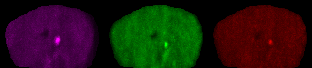

In [32]:
for i in range(42,43):
    # get frame/label
    frame, label = int(nucleus_track[i,0]), int(nucleus_track[i,1])
    frame_path = os.path.join(frames_path, f"{to_fmt(frame)}")
    # print((frame,label))

    # read signal/mask and detect features
    lbl = f"{to_fmt(label)}"
    mask = read_h5(os.path.join(frame_path, "masks.h5"), lbl)
    dcv = read_h5(os.path.join(frame_path, "deconvolves.h5"), lbl)
    with cp.cuda.Device(device):
        features = detection(dcv, dcv, mask, shape, **c["detection"])

    # make merged MIP of channels
    mips = []
    for chnl in range(len(dcv)):
        for axis in [2]:
            mip = to_mip(dcv[chnl], mask=mask, axis=axis, **c["movies"]["channels"][chnl])
            # mips.append(np.transpose(mip, axes=(1,0,2)))  # transpose
            mips.append(mip)
            print(mip.shape)
    mips = Image.fromarray(np.concatenate(mips, axis=1))

    # # show detections
    # draw, radius = ImageDraw.Draw(mips), 8
    # offset = np.sum(dcv.shape[1:3])
    # for chnl in c["detection"]["channels"]:
    #     pts = features[chnl]
    #     for j in range(len(pts)):
    #         color= "yellow" if pts[j,-1] else "black"
    #         x, y = pts[j,4] + chnl*offset, pts[j,5]
    #         draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
    #         x, y = pts[j,3] + chnl*offset + dcv.shape[2], pts[j,5]
    #         draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline=color, width=2)
    display(mips)

### Features

#### Show tracks

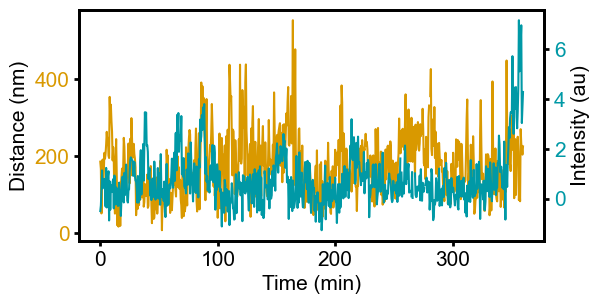

In [22]:
colors = [(0.85,0.60,0.0), (0.0,0.6,0.65)]

# iterate through tracks
path = os.path.join(nuclei_path, f"{to_fmt(nucleus)}", "tracks")
for item in os.listdir(path):
    if item[:-4].isnumeric():
        # make figure and read track from CSV
        fig, axis = plt.subplots(figsize=(6,3))
        axis.set_xlabel("Time (min)")
        track = np.loadtxt(os.path.join(path, item), delimiter=",", skiprows=1)

        # plot distances
        distances = track[:,23]
        distances[distances > 600] = np.nan
        axis.plot(track[:,1]/60, distances, color=colors[0])
        axis.set_ylabel("Distance (nm)")
        axis.tick_params(axis="y", labelcolor=colors[0])

        # plot intensities
        twin = axis.twinx()
        intensities = track[:,25]
        twin.plot(track[:,1]/60, intensities, color=colors[1])
        twin.set_ylabel("Intensity (au)")
        twin.tick_params(axis="y", labelcolor=colors[1])
        plt.show()
        break

# Beads

### Read bead movie

In [9]:
# read bead paths and get random
paths = read_beads(beads)
path = paths[np.random.randint(0, len(paths))]

path = "/mnt/dorothyshares/Jamie/Fbn2_production_imaging/beads/20260415_beads_100nm_640_488_561-06.czi"
c = read_yaml(config)
# read frame
frame = 0
signal = read_czi(path, frame)  # reading deskew
print(path)

/mnt/dorothyshares/Jamie/Fbn2_production_imaging/beads/20260415_beads_100nm_640_488_561-06.czi


In [10]:
# deskew all channels
c = read_yaml(config)
with cp.cuda.Device(device):
    deskew = deskewing(signal, **c["deskewing"])

### Detect in channels

In [11]:
# detect beads in channel
c = read_yaml(config)
with cp.cuda.Device(device):
    positions, _ = finding(deskew, **c["beads"]["finding"])

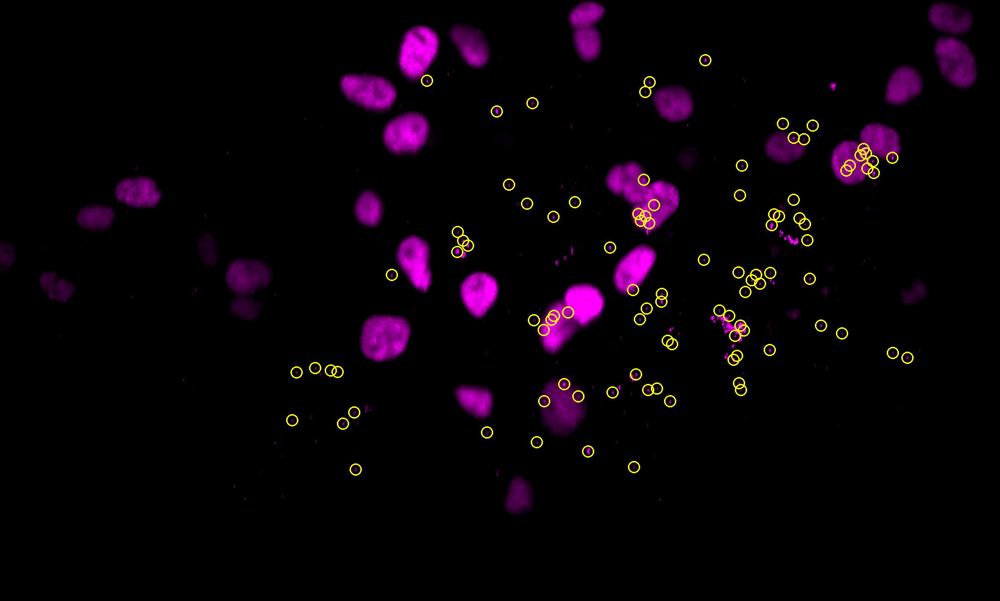

In [15]:
chnl = 0

# make MIP
mip = to_mip(deskew[chnl]/3, axis=0, **c["movies"]["channels"][chnl])
mip = Image.fromarray(np.transpose(mip, axes=(1,0,2)))

# show beads
draw, radius = ImageDraw.Draw(mip), 12
for j in range(len(positions[chnl])):
    x, y = positions[chnl][j,1], positions[chnl][j,2]
    draw.ellipse((x-radius, y-radius, x+radius, y+radius), outline="yellow", width=3)
display(mip)

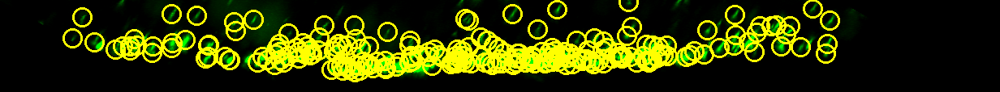

In [14]:
# make MIP and show
chnl = 1
mip = to_mip(deskew[chnl]/3, **c["movies"]["channels"][chnl], axis=1)
mip = Image.fromarray(mip)

# show beads
draw, radius = ImageDraw.Draw(mip), 12
for j in range(len(positions[chnl])):
    z, x = positions[chnl][j,0], positions[chnl][j,2]
    draw.ellipse((x-radius, z-radius, x+radius, z+radius), outline="yellow", width=3)
display(mip)

### Show PSF volume and mask

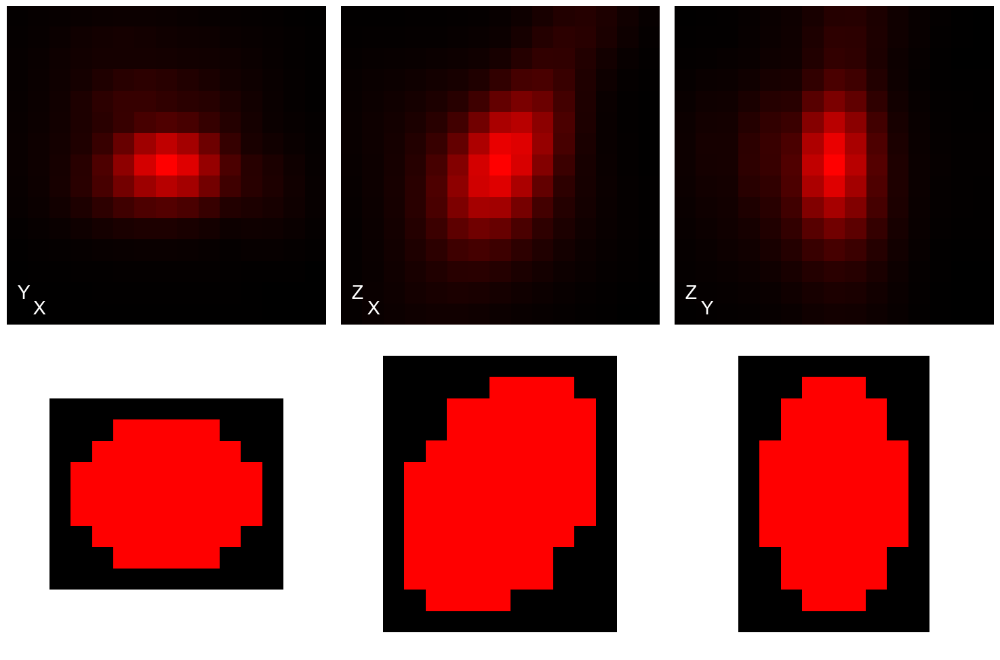

In [7]:
chnl = 2

# get kernel/shape volumes
scale = 2.0
volumes = [kernel[chnl], to_ellipsoid(scale**2 * shape[chnl])]
fig, axes = plt.subplots(2, 3, figsize=(15,10))

# show all axes
k = kernel.shape[1]
for col in range(3):
    for row in range(len(volumes)):
        # make MIP
        mip = to_mip(volumes[row], axis=col,
                     color=c["movies"]["channels"][chnl]["color"])
        # show image
        h, w = mip.shape[:2]
        axes[row,col].set(xlim=(0, k), ylim=(0, k))
        axes[row,col].imshow(mip, extent=((k-w)/2, (k+w)/2, (k-h)/2, (k+h)/2))
        axes[row,col].axis("off")

        # write dimension labels
        dims = ["Z", "Y", "X"]
        dims.pop(col)
        if row == 0:
            axes[row,col].text(0.5, 1.25, dims[0], fontsize=20, color="w")
            axes[row,col].text(1.25, 0.5, dims[1], fontsize=20, color="w")
plt.tight_layout()
plt.show()